# Import Libraries

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from tqdm import tqdm
from lib_file import lib_path
import contractions
from textblob import TextBlob
import nltk
nltk.download('punkt')
nltk.download('wordnet')
from nltk.corpus import stopwords

# Load stopwords
stop_words = set(stopwords.words('english'))


input\cleaned_data.csv
input\Depression_Detection.csv
input\glove.6B.50d.txt


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\DELL\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\DELL\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


# Data Loading

In [2]:
df = pd.read_csv('IMDB Dataset.csv')

***Preliminary Analysis***

In [3]:
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [4]:
df.shape

(50000, 2)

In [5]:
df['sentiment'].unique().tolist()

['positive', 'negative']

In [6]:
df['sentiment'].value_counts()

positive    25000
negative    25000
Name: sentiment, dtype: int64

# Data Preprocessing

In [7]:
df.isnull().sum()

review       0
sentiment    0
dtype: int64

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB


In [9]:
class_labels = df['sentiment'].unique().tolist()
class_labels.sort()

print(class_labels)

['negative', 'positive']


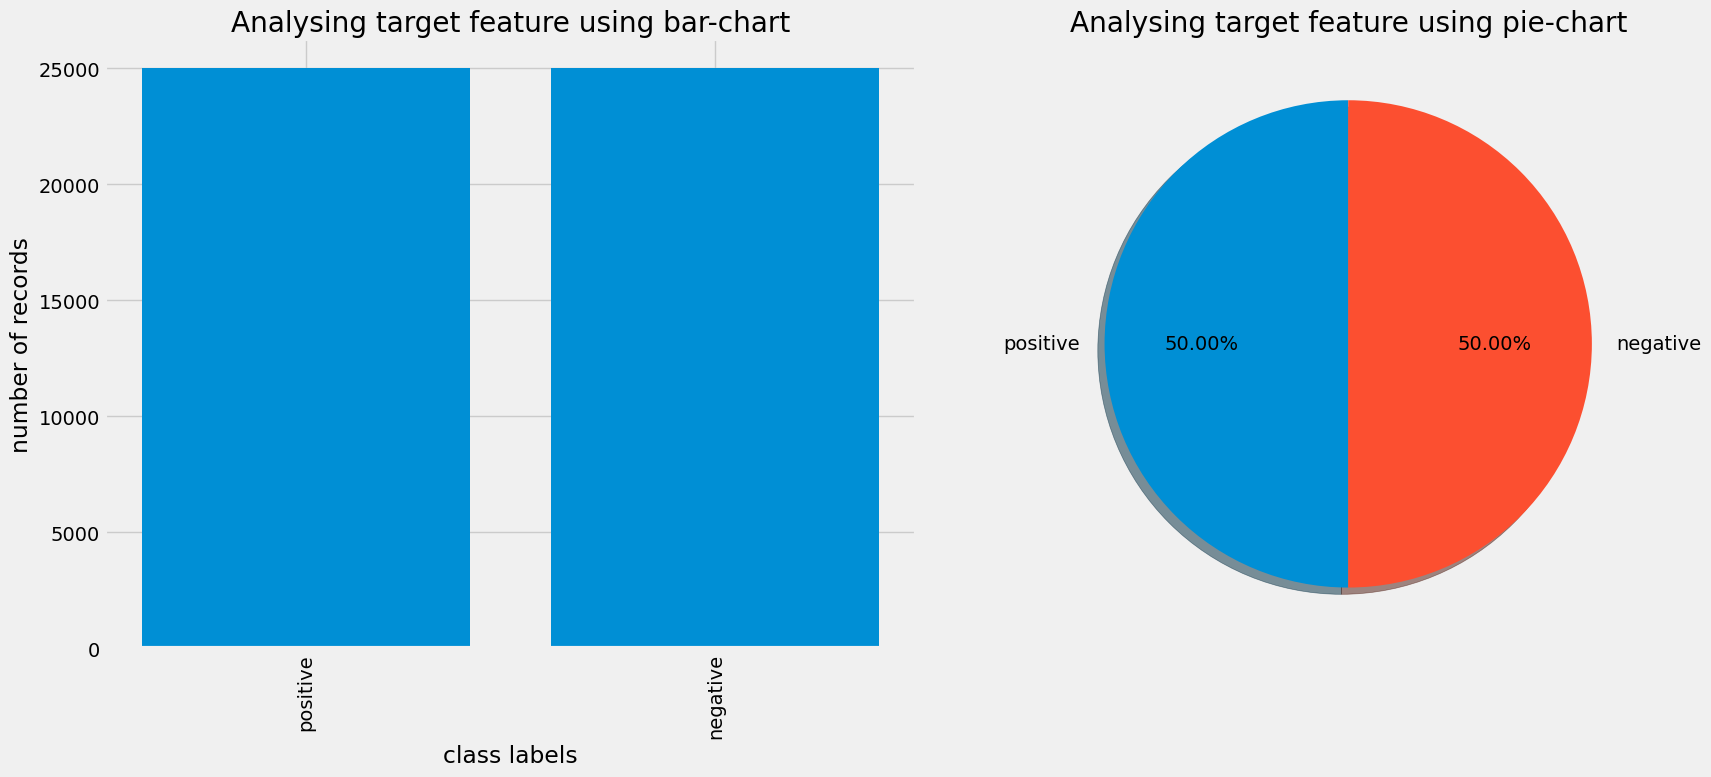

In [10]:
viz_data = dict(df['sentiment'].value_counts())

with plt.style.context(style='fivethirtyeight'):
    fig,axes = plt.subplots(nrows=1,ncols=2,figsize=(18,8))
    axes[0].bar(x=list(viz_data.keys()),
                height=list(viz_data.values()))
    axes[0].set_title(label='Analysing target feature using bar-chart')
    axes[0].set_xlabel(xlabel='class labels')
    axes[0].set_ylabel(ylabel='number of records')
    for tick in axes[0].get_xticklabels():
        tick.set_rotation(90)
    axes[1].pie(x=list(viz_data.values()),
                labels=list(viz_data.keys()),
                autopct='%.2f%%',pctdistance=0.60,
                startangle=90,
                shadow=True)
    axes[1].set_title(label='Analysing target feature using pie-chart')
    fig.tight_layout()
    plt.show()

In [11]:
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [12]:
def clean_text(text):
    # Expand contractions
    text = contractions.fix(text)
    
    # Remove HTML tags (e.g., <br />)
    text = re.sub(r'<.*?>', '', text)

    # Remove emoticons
    emoticons = [r':\)', r':\(', r':P']
    pattern = '|'.join(emoticons)
    text = re.sub(pattern, '', text)

    # Remove mentions (@user)
    text = re.sub(r'@\w+', '', text)

    # Remove hashtags (#hashtag)
    text = re.sub(r'#\w+', '', text)

    # Remove URLs (http, https, www)
    text = re.sub(r'https?://\S+|www\.\S+', '', text)

    # Remove non-alphanumeric characters (punctuation, symbols)
    text = re.sub(r'[^\w\s]', '', text)

    # Remove extra whitespaces
    text = re.sub(r'\s+', ' ', text).strip()

    # Perform lemmatization and stopword removal
    blob = TextBlob(text)
    lemmatized_words = [word.lemmatize() for word in blob.words if word.lower() not in stop_words]

    # Join the words back into a sentence
    text = " ".join(lemmatized_words)

    # Convert to lowercase
    text = text.lower()

    return text


In [13]:
sentences = []

for sentence in tqdm(df['review'].values.tolist()):
    try:
        sentences.append(clean_text(sentence))
    except:
        sentences.append("empty")

100%|███████████████████████████████████████████████████████████████████████████| 50000/50000 [01:29<00:00, 558.19it/s]


In [14]:
df['cleaned_text'] = sentences
df.head()

,review,sentiment,cleaned_text
0,One of the other reviewers has mentioned that ...,positive,one reviewer mentioned watching 1 oz episode h...
1,A wonderful little production. <br /><br />The...,positive,wonderful little production filming technique ...
2,I thought this was a wonderful way to spend ti...,positive,thought wonderful way spend time hot summer we...
3,Basically there's a family where a little boy ...,negative,basically family little boy jake think zombie ...
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,petter matteis love time money visually stunni...


In [15]:
df = df.drop(df.loc[df['cleaned_text'] == "empty"].index, axis=0)
df.shape

(50000, 3)

In [16]:
df['sequence_length'] = df['cleaned_text'].apply(lambda x: len(str(x).split(' ')))
df.head()

,review,sentiment,cleaned_text,sequence_length
0,One of the other reviewers has mentioned that ...,positive,one reviewer mentioned watching 1 oz episode h...,163
1,A wonderful little production. <br /><br />The...,positive,wonderful little production filming technique ...,84
2,I thought this was a wonderful way to spend ti...,positive,thought wonderful way spend time hot summer we...,85
3,Basically there's a family where a little boy ...,negative,basically family little boy jake think zombie ...,64
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,petter matteis love time money visually stunni...,125


In [17]:
df['sequence_length'].min()

3

In [18]:
df['sequence_length'].max()

1417

In [19]:
count_less_equal_200 = len(df[df['sequence_length'] <= 200])

print("Count of records with sequence_length <= 200:", count_less_equal_200)

Count of records with sequence_length <= 200: 43259


In [20]:
df.loc[df['sequence_length'] <= 4]

,review,sentiment,cleaned_text,sequence_length
19874,This movie is terrible but it has some good ef...,negative,movie terrible good effect,4
27521,"Read the book, forget the movie!",negative,read book forget movie,4
28920,Primary plot!Primary direction!Poor interpreta...,negative,primary plotprimary directionpoor interpretation,4
31072,"What a script, what a story, what a mess!",negative,script story mess,3


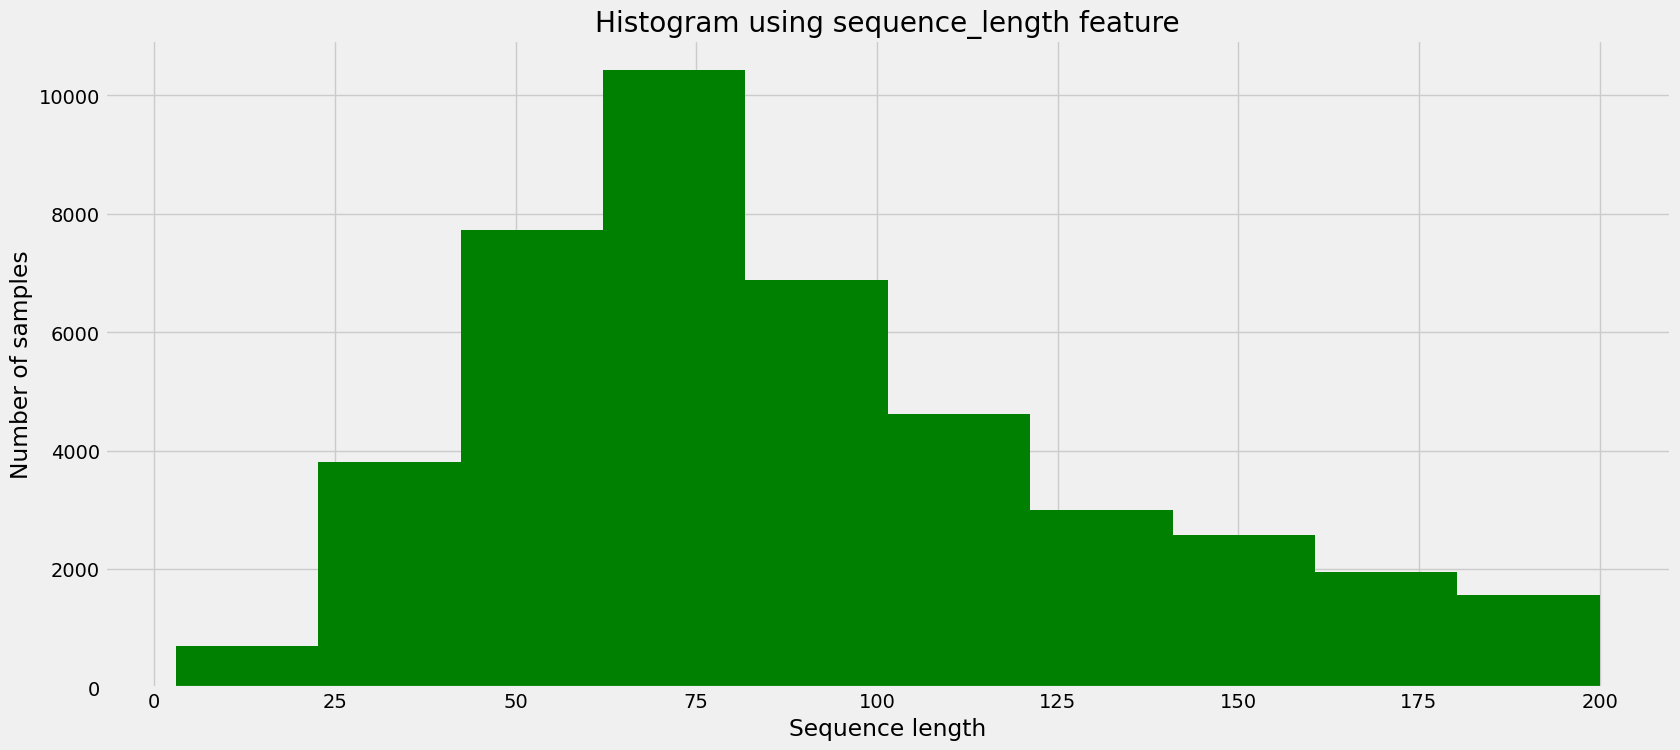

In [21]:
text_df = df.loc[(df['sequence_length'] >= 3) & (df['sequence_length'] <= 200)]

with plt.style.context(style='fivethirtyeight'):
    plt.figure(figsize=(18,8))
    plt.hist(text_df['sequence_length'].values,color='green')
    plt.title(label='Histogram using sequence_length feature')
    plt.xlabel(xlabel='Sequence length')
    plt.ylabel(ylabel='Number of samples')
    plt.show()

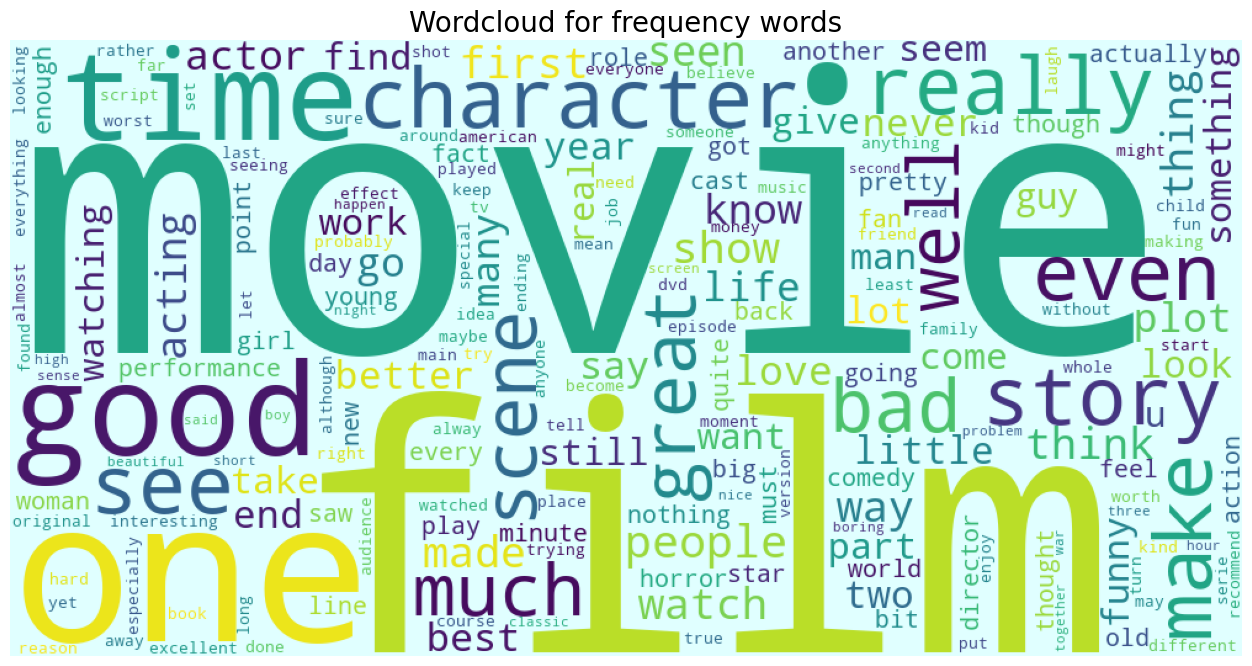

In [22]:
from wordcloud import WordCloud, STOPWORDS
stopwords=set(STOPWORDS)
from nltk import FreqDist
doc_list = list(text_df['cleaned_text'].values)
words = [sublist for sublist in doc_list]
word= FreqDist(words)
plt.figure(figsize=(18,8))
wordcloud = WordCloud(width = 1000,background_color ='lightcyan', height = 500,stopwords=stopwords,collocations=False).generate(",".join(str(v) for v in word))  
plt.imshow(wordcloud)
plt.axis("off")
plt.title(label='Wordcloud for frequency words',fontsize=20)
plt.show()

In [23]:
text_df = text_df[['cleaned_text','sentiment']]

In [24]:
text_df.head()

,cleaned_text,sentiment
0,one reviewer mentioned watching 1 oz episode h...,positive
1,wonderful little production filming technique ...,positive
2,thought wonderful way spend time hot summer we...,positive
3,basically family little boy jake think zombie ...,negative
4,petter matteis love time money visually stunni...,positive


In [25]:
text_df.shape

(43259, 2)

In [26]:
text_df['sentiment'].value_counts()

negative    21852
positive    21407
Name: sentiment, dtype: int64

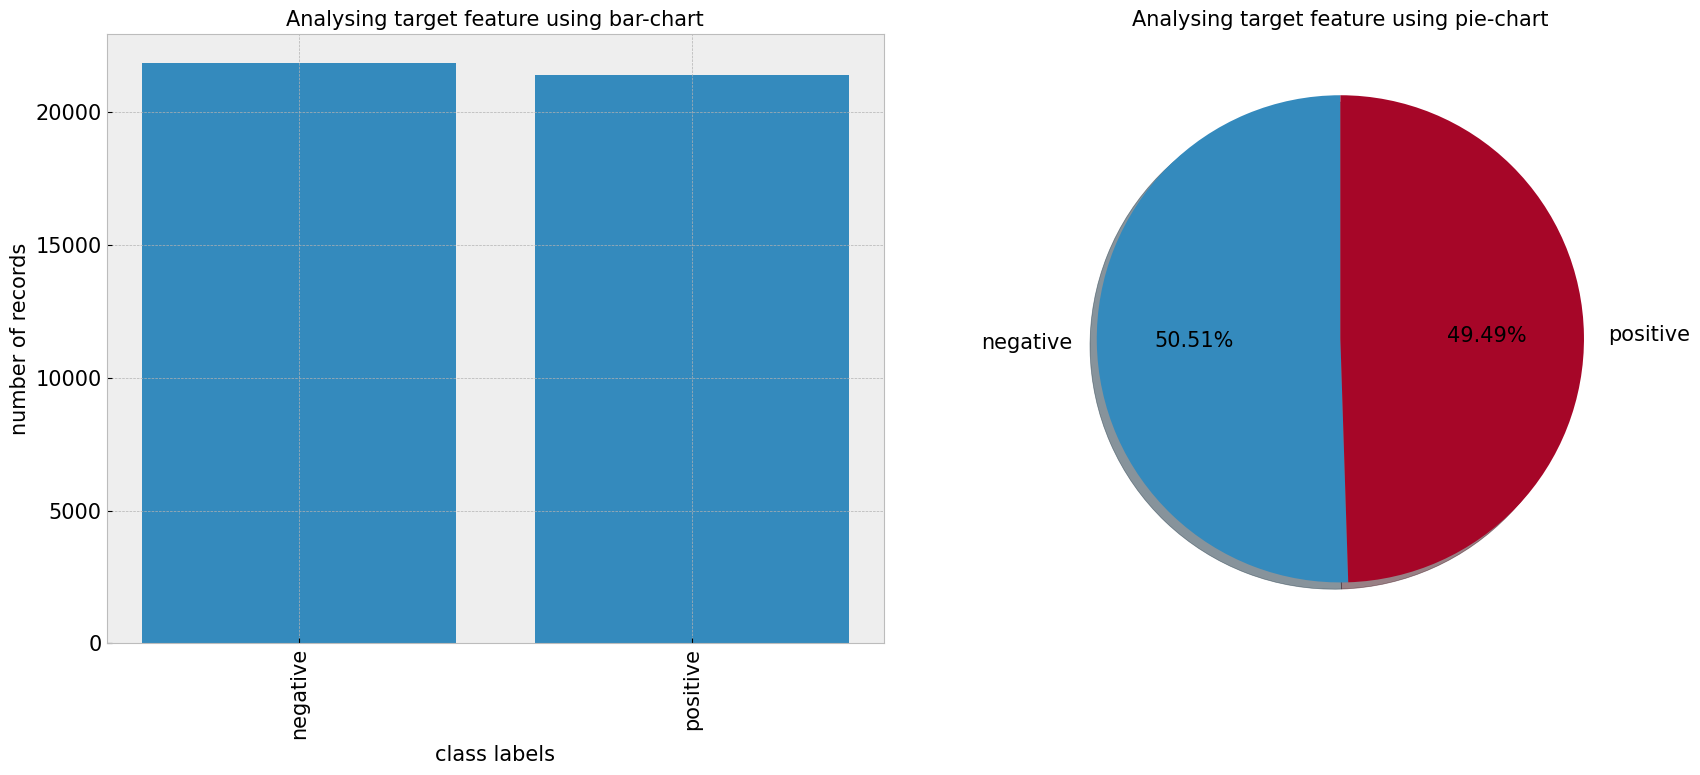

In [27]:
viz_data = dict(text_df['sentiment'].value_counts())

with plt.style.context(style='bmh'):
    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(18, 8))

    plt.rcParams['font.size'] = 15

    axes[0].bar(x=list(viz_data.keys()),
                height=list(viz_data.values()))
    axes[0].set_title(label='Analysing target feature using bar-chart', fontsize=15)
    axes[0].set_xlabel(xlabel='class labels', fontsize=15)
    axes[0].set_ylabel(ylabel='number of records', fontsize=15)
    for tick in axes[0].get_xticklabels():
        tick.set_rotation(90)
    axes[0].tick_params(axis='both', labelsize=15)

    axes[1].pie(x=list(viz_data.values()),
                labels=list(viz_data.keys()),
                autopct='%.2f%%', pctdistance=0.60,
                startangle=90,
                shadow=True)
    axes[1].set_title(label='Analysing target feature using pie-chart', fontsize=15)

    fig.tight_layout()
    plt.show()

In [29]:
text_df['sentiment'].value_counts()

negative    21852
positive    21407
Name: sentiment, dtype: int64

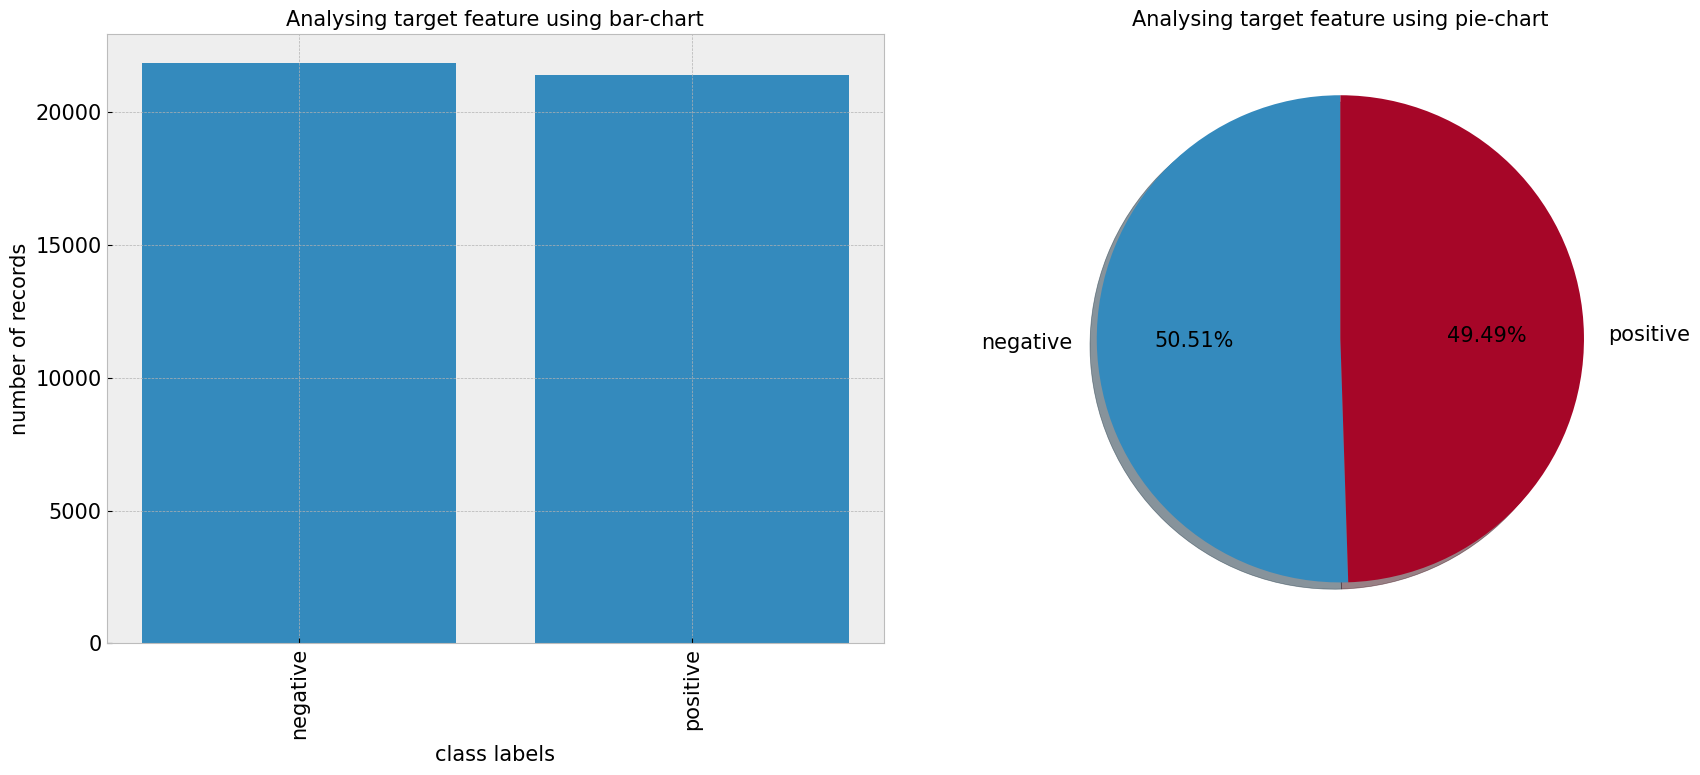

In [30]:
viz_data = dict(text_df['sentiment'].value_counts())

with plt.style.context(style='bmh'):
    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(18, 8))

    plt.rcParams['font.size'] = 15

    axes[0].bar(x=list(viz_data.keys()),
                height=list(viz_data.values()))
    axes[0].set_title(label='Analysing target feature using bar-chart', fontsize=15)
    axes[0].set_xlabel(xlabel='class labels', fontsize=15)
    axes[0].set_ylabel(ylabel='number of records', fontsize=15)
    for tick in axes[0].get_xticklabels():
        tick.set_rotation(90)
    axes[0].tick_params(axis='both', labelsize=15)

    axes[1].pie(x=list(viz_data.values()),
                labels=list(viz_data.keys()),
                autopct='%.2f%%', pctdistance=0.60,
                startangle=90,
                shadow=True)
    axes[1].set_title(label='Analysing target feature using pie-chart', fontsize=15)

    fig.tight_layout()
    plt.show()

In [31]:
text_df.to_csv("input/cleaned_data.csv", index=False)

---